# 05 · Selección del modelo ganador, métrica de negocio y Model Registry

Pasos, en orden:
1. Comparo ganador y segundo mejor con la CV (media, desviación y diferencia pareada pliegue a pliegue).
2. Elijo el umbral de decisión con predicciones *out-of-fold* del **entrenamiento**, según el costo de cada error.
3. Evalúo ambos **una sola vez** en el hold-out.
4. Comparo costo y explicabilidad.
5. Registro `anticipar-mora-modelo` con los alias `champion` y `challenger`.

In [1]:
import sys, time, warnings
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, mlflow
from mlflow import MlflowClient
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict, learning_curve
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from sklearn.inspection import permutation_importance
from src.datos import cargar_obt, dividir, esquema_cv, SEMILLA
from src.pipeline import pipeline_regla
from src import tracking, negocio
sns.set_theme(style='whitegrid'); IMG = '../docs/img/'
tracking.configurar(); cliente = MlflowClient(); exp = mlflow.get_experiment_by_name(tracking.EXPERIMENTO)
obt, meta = cargar_obt(); X_train, X_test, y_train, y_test = dividir(obt)
tun = mlflow.search_runs([exp.experiment_id], filter_string="tags.fase = 'tuning'", order_by=['metrics.cv_roc_auc_mean DESC'])
tun[['tags.modelo','metrics.cv_roc_auc_mean','metrics.cv_roc_auc_std','metrics.train_roc_auc','metrics.brecha_roc_auc','metrics.mejora_vs_default','run_id']]

,tags.modelo,metrics.cv_roc_auc_mean,metrics.cv_roc_auc_std,metrics.train_roc_auc,metrics.brecha_roc_auc,metrics.mejora_vs_default,run_id
0,hist_gradient_boosting,0.787338,0.004079,0.832838,0.045500,0.003120,207f2304a38841f6bc0a3e63113d582f
1,lightgbm,0.786959,0.004366,0.829211,0.042252,0.004735,97be9181f5a84fcf9f0e3cd795c73969
2,logistic_regression,0.781508,0.005906,0.786540,0.005032,0.000945,a96ee950de3e408e9a83b120c98bdf8f


## 1. Ganador vs segundo mejor en CV

In [2]:
a, b = tun.iloc[0], tun.iloc[1]
def folds(nombre):
    t = pd.read_csv(f'../docs/tuning_{nombre}.csv'); b = t.loc[t.rank_test_roc_auc.idxmin()]
    return np.array([b[f'split{i}_test_roc_auc'] for i in range(5)])
fa, fb = folds(a['tags.modelo']), folds(b['tags.modelo'])
dif = fa - fb
comp = pd.DataFrame({'pliegue': range(1, 6), a['tags.modelo']: fa, b['tags.modelo']: fb, 'diferencia': dif})
print(f"{a['tags.modelo']} - {b['tags.modelo']}: diferencia media {dif.mean():+.4f} | desv. de la diferencia {dif.std(ddof=1):.4f} | gana en {(dif>0).sum()}/5 pliegues")
print(f"Desv. entre pliegues: {fa.std():.4f} y {fb.std():.4f}")
supera = abs(dif.mean()) > max(fa.std(), fb.std())
criterios = pd.DataFrame({r['tags.modelo']: {'cv_auc': r['metrics.cv_roc_auc_mean'], 'cv_std': r['metrics.cv_roc_auc_std'],
                                             'brecha_train_cv': r['metrics.brecha_roc_auc'], 'seg_ajuste': r['metrics.fit_seconds_mean']}
                          for _, r in tun.head(2).iterrows()}).T
if supera:
    campeon, retador = a, b; razon = 'mayor AUC en CV con diferencia mayor que la variación entre pliegues'
else:
    # Empate estadístico: desempate con criterios conocidos ANTES del hold-out (no se mira el test)
    orden = criterios.sort_values(['brecha_train_cv', 'seg_ajuste']).index
    campeon = tun.set_index('tags.modelo').loc[orden[0]].copy(); campeon['tags.modelo'] = orden[0]; campeon['run_id'] = tun.set_index('tags.modelo').loc[orden[0], 'run_id']
    retador = tun.set_index('tags.modelo').loc[orden[1]].copy(); retador['tags.modelo'] = orden[1]; retador['run_id'] = tun.set_index('tags.modelo').loc[orden[1], 'run_id']
    razon = 'empate en AUC (diferencia < variación entre pliegues): gana el de menor brecha de sobreajuste y menor costo'
print('¿La diferencia supera la variación entre pliegues?', 'Sí' if supera else 'No')
print(f"=> Campeón: {campeon['tags.modelo']} | Retador: {retador['tags.modelo']} | Criterio: {razon}")
display(criterios.round(4))
comp.round(4)

hist_gradient_boosting - lightgbm: diferencia media +0.0004 | desv. de la diferencia 0.0008 | gana en 3/5 pliegues
Desv. entre pliegues: 0.0041 y 0.0044
¿La diferencia supera la variación entre pliegues? No
=> Campeón: lightgbm | Retador: hist_gradient_boosting | Criterio: empate en AUC (diferencia < variación entre pliegues): gana el de menor brecha de sobreajuste y menor costo


,cv_auc,cv_std,brecha_train_cv,seg_ajuste
hist_gradient_boosting,0.7873,0.0041,0.0455,1.9002
lightgbm,0.7870,0.0044,0.0423,1.0976


,pliegue,hist_gradient_boosting,lightgbm,diferencia
0,1,0.7880,0.7871,0.0009
1,2,0.7874,0.7860,0.0014
2,3,0.7797,0.7794,0.0003
3,4,0.7912,0.7917,-0.0005
4,5,0.7905,0.7907,-0.0002


## 2. Umbral de decisión por costo (solo con entrenamiento)

Métrica de negocio del PSet 1: **Ahorro = VP · saldo medio · t_éxito − (VP + FP) · c_contacto**.

| Parámetro | Valor | Fuente |
|---|---|---|
| Saldo medio en riesgo | media de `bill_amt_m1` de los morosos del entrenamiento | datos |
| t_éxito | 30 % (sensibilidad: 10 % y 50 %) | supuesto del PSet 1 |
| c_contacto | NT$ 500 por cliente contactado | supuesto: llamada más gestión de la oferta |
| Capacidad | 20 % de la cartera por mes | restricción del call center (PSet 1) |

Un falso negativo (una mora no contactada) cuesta en promedio `saldo · t` ≈ NT$ 14 mil de pérdida evitable. Un falso positivo cuesta NT$ 500. Como el error caro es el FN, el umbral económico sin restricción es muy bajo, porque convendría llamar a casi todos. En la práctica **la capacidad del call center es la que limita**.

La política queda así: contactar a quien tenga p ≥ u, dentro del 20 % de mayor riesgo. `u` se elige maximizando el ahorro OOF. El **corte efectivo** es la probabilidad del último cliente que entra en la capacidad. Para comparar con la regla de forma justa, también evalúo el modelo **contactando al mismo número de clientes que la regla**.

In [3]:
saldo_medio = float(X_train.loc[y_train == 1, 'bill_amt_m1'].mean())
modelos = {r['tags.modelo']: mlflow.sklearn.load_model(f"runs:/{r.run_id}/modelo") for _, r in tun.head(2).iterrows()}
oof = {n: cross_val_predict(clone(p), X_train, y_train, cv=esquema_cv(), method='predict_proba')[:, 1] for n, p in modelos.items()}
oof['regla_negocio'] = pipeline_regla().fit(X_train).predict_proba(X_train)[:, 1]
umbrales = {}
k_regla = int((oof['regla_negocio'] >= .5).sum())
for n, sc in oof.items():
    if n == 'regla_negocio':
        umbrales[n] = {'umbral': 0.5, 'corte_efectivo': 0.5, 'ahorro_oof': negocio.ahorro(y_train, sc >= .5, saldo_medio), 'contactos': k_regla}
        continue
    u, a_, grid, vals = negocio.elegir_umbral(y_train, sc, saldo_medio)
    libre = [negocio.ahorro(y_train, sc >= g, saldo_medio) for g in grid]
    umbrales[n] = {'umbral': u, 'corte_efectivo': negocio.corte_capacidad(sc), 'ahorro_oof': a_, 'contactos': int(negocio.contactar_top(sc, u).sum()),
                   'umbral_sin_capacidad': float(grid[int(np.argmax(libre))]), 'ahorro_sin_capacidad': float(max(libre)),
                   'ahorro_igual_volumen_regla': negocio.ahorro(y_train, negocio.contactar_k(sc, k_regla), saldo_medio),
                   'grid': grid, 'vals': vals}
print(f'Saldo medio en riesgo: NT$ {saldo_medio:,.0f} | costo de un FN ≈ NT$ {saldo_medio*negocio.T_EXITO:,.0f} vs FP = NT$ {negocio.C_CONTACTO:,.0f}')
print(f'La regla contacta a {k_regla:,} clientes ({k_regla/len(y_train):.1%}): más que la capacidad del 20%.')
tabla_umbral = pd.DataFrame({n: {k: v for k, v in d.items() if k not in ('grid','vals')} for n, d in umbrales.items()}).T
tabla_umbral.to_csv('../docs/umbrales_oof.csv'); tabla_umbral

Saldo medio en riesgo: NT$ 47,967 | costo de un FN ≈ NT$ 14,390 vs FP = NT$ 500
La regla contacta a 5,494 clientes (22.9%): más que la capacidad del 20%.


,umbral,corte_efectivo,ahorro_oof,contactos,umbral_sin_capacidad,ahorro_sin_capacidad,ahorro_igual_volumen_regla
hist_gradient_boosting,0.05,0.335285,3.702871e+07,4800.0,0.05,6.427621e+07,3.987630e+07
lightgbm,0.05,0.340523,3.697115e+07,4800.0,0.05,6.429676e+07,3.976118e+07
regla_negocio,0.50,0.500000,3.709903e+07,5494.0,NaN,NaN,NaN


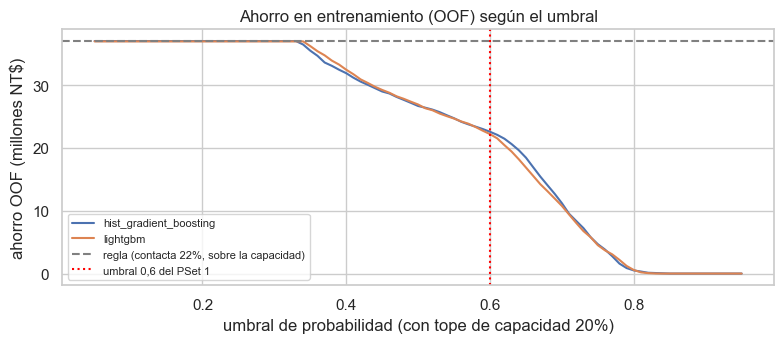

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for n in modelos: ax.plot(umbrales[n]['grid'], umbrales[n]['vals']/1e6, label=n)
ax.axhline(umbrales['regla_negocio']['ahorro_oof']/1e6, c='gray', ls='--', label='regla (contacta 22%, sobre la capacidad)')
ax.axvline(0.6, c='red', ls=':', label='umbral 0,6 del PSet 1')
ax.set_xlabel('umbral de probabilidad (con tope de capacidad 20%)'); ax.set_ylabel('ahorro OOF (millones NT$)'); ax.legend(fontsize=8); ax.set_title('Ahorro en entrenamiento (OOF) según el umbral')
plt.tight_layout(); plt.savefig(IMG+'umbral_ahorro.png', dpi=150); plt.show()

## 3. Evaluación única en el hold-out

In [5]:
filas, proba_test, t_inf = [], {}, {}
proba_regla = pipeline_regla().fit(X_train).predict_proba(X_test)[:, 1]
for n, p in [(campeon['tags.modelo'], modelos[campeon['tags.modelo']]), (retador['tags.modelo'], modelos[retador['tags.modelo']]), ('regla_negocio', pipeline_regla().fit(X_train))]:
    t0 = time.perf_counter(); s = p.predict_proba(X_test)[:, 1]; t_inf[n] = (time.perf_counter() - t0) / len(X_test) * 1000
    proba_test[n] = s; u = umbrales[n]['umbral']
    contactar = negocio.contactar_top(s, u) if n != 'regla_negocio' else s >= .5
    rec, prec = negocio.recall_precision_top(y_test, s)
    fila = {'modelo': n, 'test_roc_auc': roc_auc_score(y_test, s), 'test_average_precision': average_precision_score(y_test, s),
            'test_recall_top20': rec, 'test_precision_top20': prec, 'umbral': u, 'contactados': int(contactar.sum()),
            'moras_detectadas': int((contactar & (y_test.values == 1)).sum()), 'test_ahorro_NT$': negocio.ahorro(y_test, contactar, saldo_medio),
            'ms_por_cliente': t_inf[n]}
    if n != 'regla_negocio':
        fila['corte_efectivo'] = negocio.corte_capacidad(s)
        fila['test_ahorro_umbral_0.6'] = negocio.ahorro(y_test, negocio.contactar_top(s, 0.6), saldo_medio)
        fila['contactados_umbral_0.6'] = int(negocio.contactar_top(s, 0.6).sum())
        k_r = int((proba_regla >= .5).sum()); c_k = negocio.contactar_k(s, k_r)
        fila['test_ahorro_igual_volumen_regla'] = negocio.ahorro(y_test, c_k, saldo_medio)
        fila['moras_igual_volumen_regla'] = int((c_k & (y_test.values == 1)).sum())
        for t in (0.10, 0.30, 0.50):
            fila[f'ahorro_t{int(t*100)}'] = negocio.ahorro(y_test, contactar, saldo_medio, t_exito=t)
    else:
        for t in (0.10, 0.30, 0.50):
            fila[f'ahorro_t{int(t*100)}'] = negocio.ahorro(y_test, contactar, saldo_medio, t_exito=t)
    filas.append(fila)
test = pd.DataFrame(filas).set_index('modelo')
base = test.loc['regla_negocio', 'test_ahorro_NT$']
test['ahorro_extra_vs_regla_NT$'] = test['test_ahorro_NT$'] - base
test['ahorro_extra_igual_volumen_NT$'] = test.get('test_ahorro_igual_volumen_regla') - base
test.to_csv('../docs/resultados_test.csv'); test.round(4).T

modelo,lightgbm,hist_gradient_boosting,regla_negocio
test_roc_auc,7.829000e-01,7.833000e-01,6.776000e-01
test_average_precision,5.602000e-01,5.598000e-01,3.591000e-01
test_recall_top20,5.162000e-01,5.124000e-01,4.514000e-01
test_precision_top20,5.708000e-01,5.667000e-01,4.992000e-01
umbral,5.000000e-02,5.000000e-02,5.000000e-01
contactados,1.200000e+03,1.200000e+03,1.324000e+03
moras_detectadas,6.850000e+02,6.800000e+02,6.600000e+02
test_ahorro_NT$,9.257179e+06,9.185228e+06,8.835428e+06
ms_por_cliente,1.790000e-02,6.100000e-03,0.000000e+00
corte_efectivo,3.401000e-01,3.420000e-01,NaN


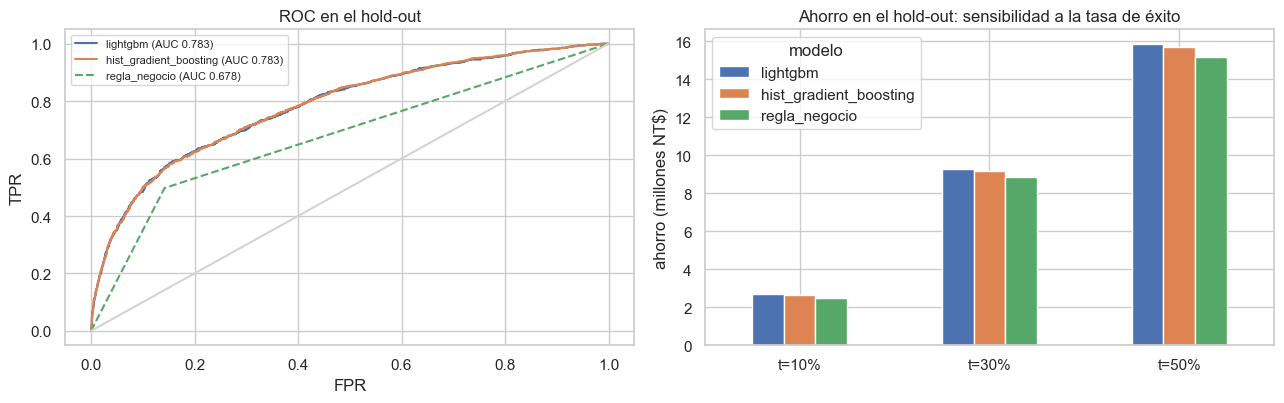

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for n, s in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test, s); ax[0].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(y_test, s):.3f})", ls='--' if n=='regla_negocio' else '-')
ax[0].plot([0,1],[0,1], c='lightgray'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(fontsize=8); ax[0].set_title('ROC en el hold-out')
sens = test[['ahorro_t10','ahorro_t30','ahorro_t50']].T/1e6; sens.index = ['t=10%','t=30%','t=50%']
sens.plot.bar(ax=ax[1]); ax[1].set_ylabel('ahorro (millones NT$)'); ax[1].set_title('Ahorro en el hold-out: sensibilidad a la tasa de éxito'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig(IMG+'test_roc_ahorro.png', dpi=150); plt.show()

## 4. Costo y explicabilidad

,"segundos_ajuste (CV, media)",ms_inferencia_por_cliente
hist_gradient_boosting,1.900,0.006
lightgbm,1.098,0.018


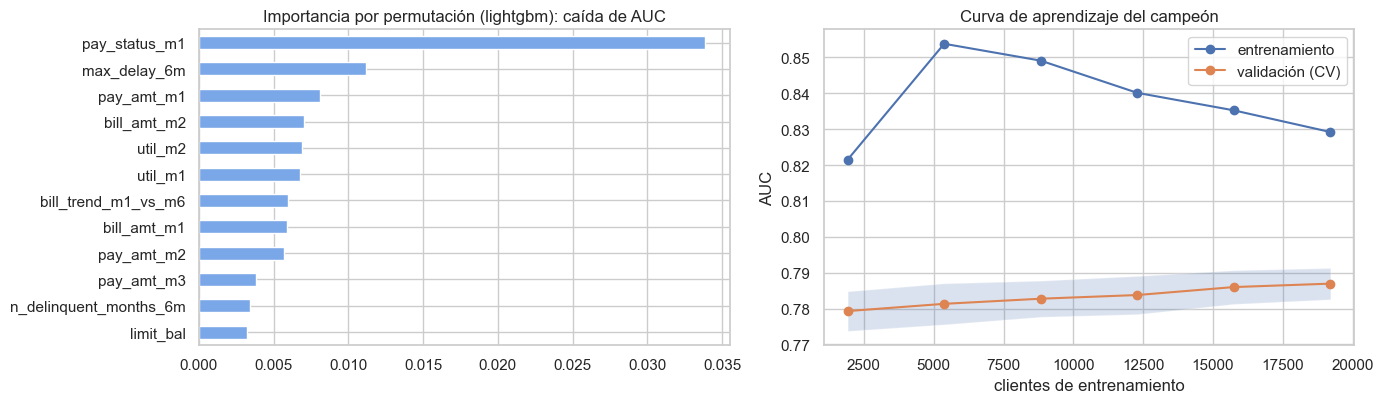

pay_status_m1             0.0338
max_delay_6m              0.0112
pay_amt_m1                0.0081
bill_amt_m2               0.0071
util_m2                   0.0069
util_m1                   0.0068
bill_trend_m1_vs_m6       0.0060
bill_amt_m1               0.0059
pay_amt_m2                0.0057
pay_amt_m3                0.0038
n_delinquent_months_6m    0.0034
limit_bal                 0.0032
dtype: float64

In [7]:
n_c = campeon['tags.modelo']; pipe_c = modelos[n_c]
costo = pd.DataFrame({n: {'segundos_ajuste (CV, media)': tun.set_index('tags.modelo').loc[n, 'metrics.fit_seconds_mean'],
                          'ms_inferencia_por_cliente': t_inf[n]} for n in modelos}).T
display(costo.round(3))
muestra = X_train.sample(4000, random_state=SEMILLA)
pi = permutation_importance(pipe_c, muestra, y_train.loc[muestra.index], scoring='roc_auc', n_repeats=5, random_state=SEMILLA, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=muestra.columns).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
imp[::-1].plot.barh(ax=ax[0], color='#7aa7e8'); ax[0].set_title(f'Importancia por permutación ({n_c}): caída de AUC')
tam, tr, va = learning_curve(clone(pipe_c), X_train, y_train, cv=esquema_cv(), scoring='roc_auc', train_sizes=np.linspace(.1, 1, 6), n_jobs=-1)
ax[1].plot(tam, tr.mean(1), 'o-', label='entrenamiento'); ax[1].plot(tam, va.mean(1), 'o-', label='validación (CV)')
ax[1].fill_between(tam, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=.2); ax[1].set_xlabel('clientes de entrenamiento'); ax[1].set_ylabel('AUC'); ax[1].legend(); ax[1].set_title('Curva de aprendizaje del campeón')
plt.tight_layout(); plt.savefig(IMG+'explicabilidad.png', dpi=150); plt.show()
imp.round(4)

## 5. Registro en el Model Registry

Cada modelo tiene una corrida `final` que registra sus métricas de prueba, el umbral y los parámetros de negocio. Después se registra la versión del modelo y se le asigna el alias.

In [8]:
registro = {}
for alias, fila in [('champion', campeon), ('challenger', retador)]:
    n = fila['tags.modelo']; r = test.loc[n]
    with mlflow.start_run(run_name=f'final_{alias}_{n}') as run:
        mlflow.set_tags({'fase': 'final', 'familia': fila['tags.familia'], 'modelo': n, 'alias': alias, 'git_commit': tracking.commit_git(),
                         'run_tuning_origen': fila.run_id})
        tracking.log_datos(meta)
        mlflow.log_params({'politica': 'contactar top 20% con p >= umbral', 'umbral_decision': umbrales[n]['umbral'],
                           'corte_efectivo_train_oof': round(umbrales[n]['corte_efectivo'], 4), 'criterio_seleccion': razon[:250], 'saldo_medio_NT': round(saldo_medio, 2), 't_exito': negocio.T_EXITO,
                           'c_contacto_NT': negocio.C_CONTACTO, 'capacidad': negocio.CAPACIDAD, 'semilla': SEMILLA})
        mlflow.log_params({k.replace('params.', ''): v for k, v in fila.items() if str(k).startswith('params.best_') and pd.notna(v)})
        mlflow.log_metrics({'cv_roc_auc_mean': fila['metrics.cv_roc_auc_mean'], 'cv_roc_auc_std': fila['metrics.cv_roc_auc_std'],
                            'test_roc_auc': r.test_roc_auc, 'test_average_precision': r.test_average_precision,
                            'test_recall_top20': r.test_recall_top20, 'test_precision_top20': r.test_precision_top20,
                            'test_ahorro_NT': r['test_ahorro_NT$'], 'test_ahorro_extra_vs_regla_NT': r['ahorro_extra_vs_regla_NT$'],
                            'test_ahorro_igual_volumen_regla_NT': r['test_ahorro_igual_volumen_regla'], 'test_corte_efectivo': r['corte_efectivo'],
                            'ms_inferencia_por_cliente': r.ms_por_cliente})
        info = tracking.log_modelo(modelos[n], X_train, registrar=tracking.MODELO_REGISTRO)
    version = info.registered_model_version
    cliente.set_registered_model_alias(tracking.MODELO_REGISTRO, alias, version)
    cliente.set_model_version_tag(tracking.MODELO_REGISTRO, version, 'test_roc_auc', f'{r.test_roc_auc:.6f}')
    registro[alias] = {'modelo': n, 'run_id': run.info.run_id, 'version': version, 'test_roc_auc': r.test_roc_auc, 'test_ahorro_NT$': r['test_ahorro_NT$']}
pd.DataFrame(registro).T.to_csv('../docs/registro.csv'); pd.DataFrame(registro).T

2026/11/18 20:17:08 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Successfully registered model 'anticipar-mora-modelo'.
2026/11/18 20:17:08 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: anticipar-mora-modelo, version 1


Created version '1' of model 'anticipar-mora-modelo'.


2026/11/18 20:17:09 INFO mlflow.tracking._tracking_service.client: 🏃 View run final_champion_lightgbm at: http://localhost:5001/#/experiments/1/runs/3933132ad8a945c4bf1249f8dee5b655.


2026/11/18 20:17:09 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5001/#/experiments/1.


2026/11/18 20:17:13 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'anticipar-mora-modelo' already exists. Creating a new version of this model...
2026/11/18 20:17:13 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: anticipar-mora-modelo, version 2


Created version '2' of model 'anticipar-mora-modelo'.


2026/11/18 20:17:13 INFO mlflow.tracking._tracking_service.client: 🏃 View run final_challenger_hist_gradient_boosting at: http://localhost:5001/#/experiments/1/runs/7f0f057610bb4d82a387600c41629a41.


2026/11/18 20:17:13 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5001/#/experiments/1.


,modelo,run_id,version,test_roc_auc,test_ahorro_NT$
champion,lightgbm,3933132ad8a945c4bf1249f8dee5b655,1,0.782859,9257178.553494
challenger,hist_gradient_boosting,7f0f057610bb4d82a387600c41629a41,2,0.783259,9185228.345074
